In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

In [27]:
print(df.shape)

(7043, 21)


In [28]:
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [29]:
totalCharges = (df["TotalCharges"].str.strip() == "").sum()
print(totalCharges)

11


In [30]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print((df["TotalCharges"].isna().sum()))
print(df.loc[df["TotalCharges"].isna(), "tenure"])

11
488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64


In [31]:
print(df["customerID"].duplicated().sum())

0


In [32]:
df["churn"] = (df["Churn"] == "Yes").astype(int)
print(df["churn"].mean(), df["churn"].sum())

0.2653698707936959 1869


In [33]:
for col in ["Contract", "InternetService", "PaymentMethod", "SeniorCitizen"]:
    print(df.groupby(col)["churn"].agg(["mean", "size"]).round(4))

                  mean  size
Contract                    
Month-to-month  0.4271  3875
One year        0.1127  1473
Two year        0.0283  1695
                   mean  size
InternetService              
DSL              0.1896  2421
Fiber optic      0.4189  3096
No               0.0740  1526
                             mean  size
PaymentMethod                          
Bank transfer (automatic)  0.1671  1544
Credit card (automatic)    0.1524  1522
Electronic check           0.4529  2365
Mailed check               0.1911  1612
                 mean  size
SeniorCitizen              
0              0.2361  5901
1              0.4168  1142


In [34]:
print(df.groupby("churn")[["tenure", "MonthlyCharges"]].mean().round(2))
print(df[["tenure", "MonthlyCharges", "TotalCharges", "churn"]].corr().round(3)["churn"])

       tenure  MonthlyCharges
churn                        
0       37.57           61.27
1       17.98           74.44
tenure           -0.352
MonthlyCharges    0.193
TotalCharges     -0.199
churn             1.000
Name: churn, dtype: float64


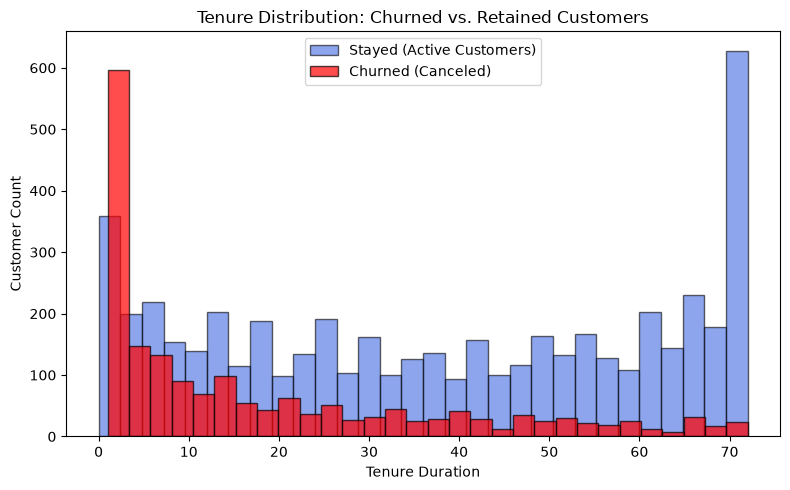

In [35]:
stayed = df[df["churn"] == 0]["tenure"]
churned = df[df["churn"] == 1]["tenure"]

plt.figure(figsize=(8,5))
plt.hist(stayed, bins=30, color="royalBlue", alpha=0.6, edgecolor="black", label="Stayed (Active Customers)")
plt.hist(churned, bins=30, color="red", alpha=0.7, edgecolor="black", label="Churned (Canceled)")
plt.title("Tenure Distribution: Churned vs. Retained Customers")
plt.xlabel("Tenure Duration")
plt.ylabel("Customer Count")
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = ["Contract", "InternetService", "PaymentMethod",
                "PaperlessBilling", "Partner", "Dependents", "TechSupport"]
X = pd.get_dummies(df[num + cat], columns=cat, dtype=int)
y = df["churn"]

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

print(X.shape, X_train.shape, X_test.shape, X_tr.shape, X_val.shape, )
print(round(y_train.mean(), 4), round(y_test.mean(), 4))
print(y_val.sum(), y_test.sum())

(7043, 23) (5634, 23) (1409, 23) (4225, 23) (1409, 23)
0.2654 0.2654
374 374


In [45]:
def make_pipe(**kw):
    return Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, **kw)),
    ])

def report(name, y_true, p, t=0.5):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    print(name, "t =", t, "| TN FP FN TP= ", tn, fp, fn, tp)
    print("Accuracy", round(accuracy_score(y_true, pred), 4))
    print("Precision", round(precision_score(y_true, pred, zero_division=0), 4))
    print("Recall", round(recall_score(y_true, pred), 4))
    print("F1", round(f1_score(y_true, pred), 4))

In [48]:
base = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
base_pred = base.predict(X_val)
print(round(accuracy_score(y_val, base_pred), 4), recall_score(y_val, base_pred))

0.7346 0.0


In [47]:
model = make_pipe().fit(X_tr, y_tr)
p_val = model.predict_proba(X_val)[:, 1]
report("model", y_val, p_val)
print("val AUC", round(roc_auc_score(y_val, p_val), 4))
print("train accracy", round(model.score(X_tr, y_tr), 4))

model t = 0.5 | TN FP FN TP=  938 97 171 203
Accuracy 0.8098
Precision 0.6767
Recall 0.5428
F1 0.6024
val AUC 0.8357
train accracy 0.7974


In [58]:
thresholds = np.round(np.arange(0.20, 0.61, 0.05), 2)
rows = []
for t in thresholds:
    pred = (p_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    rows.append((t, tn, fp, fn, tp, 
                 round(precision_score(y_val, pred), 4),
                 round(recall_score(y_val, pred), 4),
                 round(f1_score(y_val, pred), 4)))
scan = pd.DataFrame(rows, columns=["t", "tn", "fp", "fn", "tp", "precision", "recall", "f1"])
print(scan.to_string(index=False))
    

   t  tn  fp  fn  tp  precision  recall     f1
0.20 666 369  59 315     0.4605  0.8422 0.5955
0.25 727 308  72 302     0.4951  0.8075 0.6138
0.30 788 247  86 288     0.5383  0.7701 0.6337
0.35 826 209  99 275     0.5682  0.7353 0.6410
0.40 875 160 124 250     0.6098  0.6684 0.6378
0.45 904 131 145 229     0.6361  0.6123 0.6240
0.50 938  97 171 203     0.6767  0.5428 0.6024
0.55 963  72 204 170     0.7025  0.4545 0.5519
0.60 985  50 238 136     0.7312  0.3636 0.4857


In [59]:
final = make_pipe().fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]
report("TEST", y_test, p_test, t=0.50)
report("TEST", y_test, p_test, t=0.35)
print("Test AUC", round(roc_auc_score(y_test, p_test), 4))

TEST t = 0.5 | TN FP FN TP=  919 116 173 201
Accuracy 0.7949
Precision 0.6341
Recall 0.5374
F1 0.5818
TEST t = 0.35 | TN FP FN TP=  810 225 105 269
Accuracy 0.7658
Precision 0.5445
Recall 0.7193
F1 0.6198
Test AUC 0.8383


In [60]:
base_final = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline test accuracy", round(accuracy_score(y_test, base_final.predict(X_test)), 4))

Baseline test accuracy 0.7346


In [61]:
lr = final.named_steps["model"]
w = pd.Series(lr.coef_[0], index=X.columns)
odds = np.exp(w).sort_values()
print(odds.head(5).round(3).to_dict())
print(odds.tail(5).round(3).to_dict())

{'tenure': 0.292, 'Contract_Two year': 0.713, 'TechSupport_No internet service': 0.854, 'InternetService_No': 0.854, 'InternetService_DSL': 0.888}
{'PaymentMethod_Electronic check': 1.161, 'TechSupport_No': 1.173, 'InternetService_Fiber optic': 1.276, 'Contract_Month-to-month': 1.373, 'TotalCharges': 1.731}


In [62]:
m_bal = make_pipe(class_weight="balanced").fit(X_tr, y_tr)
p_bal = m_bal.predict_proba(X_val)[:, 1]
report("Balanced", y_val, p_bal)
print("AUC balanced", round(roc_auc_score(y_val, p_bal), 4))

Balanced t = 0.5 | TN FP FN TP=  743 292 78 296
Accuracy 0.7374
Precision 0.5034
Recall 0.7914
F1 0.6154
AUC balanced 0.8355


- These costs are MADE UP for practice (state that in your notes):
a retention offer costs 50 (every customer you flag gets one),
losing a customer who is not flagged costs 200.

In [65]:
OFFER, LOSS = 50, 200
def cost(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return OFFER * (fp + tp) + LOSS * fn

In [66]:
costs = pd.Series({t: cost(y_val, p_val, t) for t in thresholds})
print(costs.to_dict())
print(costs.idxmin())
print(costs.min())

{0.2: 46000, 0.25: 44900, 0.3: 43950, 0.35: 44000, 0.4: 45300, 0.45: 47000, 0.5: 49200, 0.55: 52900, 0.6: 56900}
0.3
43950


In [67]:
for t in (0.50, 0.35, 0.30): print(t, cost(y_test, p_test, t))
print("flag everyone", OFFER * len(y_test), " flag nobody", LOSS * y_test.sum())

0.5 50450
0.35 45700
0.3 45400
flag everyone 70450  flag nobody 74800


## Conclusion
- I used 7,043 telecom customers (26.5% churn, 1,869 leavers) to predict
who is likely to leave, so the company can call them with a retention
offer. A model that always says "stayed" already scores 0.7346 accuracy
with recall 0, so accuracy alone cannot be trusted here. Logistic
regression reached a validation AUC of 0.8357 and, at the default
threshold of 0.5, a test accuracy of 0.7949 (0.0603 above the baseline),
but it found only 201 of the 374 real leavers (recall 0.5374). Because a
missed leaver costs more than a wasted offer, I chose recall as the
metric, and I decided the rule BEFORE looking at the table: among
thresholds with validation recall of at least 0.70, take the one with
the best F1. That picked threshold 0.35 (validation recall 0.7353, F1
0.6410). On the test set, used once, threshold 0.35 gave recall 0.7193,
precision 0.5445 and F1 0.6198: the model flags 494 customers and 269 of
them really leave, so it catches 68 more leavers than at 0.5 (201 to
269), although accuracy fell to 0.7658. The strongest drivers were
tenure (odds ratio 0.292, long-time customers are far less likely to
leave) and contract type (month-to-month 1.373, two-year 0.713); in the
EDA, month-to-month churn was 0.4271 against 0.0283 for two-year, so
offering discounts to move month-to-month customers to longer contracts
is a sensible action. Caveats: the test set has only 1,409 customers
(374 leavers), so every score is an estimate from one split, and
TotalCharges overlaps with tenure and MonthlyCharges, so single weights
should be read with caution. A next step is a model that is not a
straight line (decision trees and forests).